In [135]:
import kagglehub
path = kagglehub.dataset_download("shwetabh123/mall-customers")

Using Colab cache for faster access to the 'mall-customers' dataset.


In [136]:
import os
os.listdir(path)

['Mall_Customers.csv']

In [137]:
import pandas as pd
df=pd.read_csv(path+'/Mall_Customers.csv')

In [138]:
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [139]:
df.shape

(200, 5)

In [140]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Genre                   200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [141]:
df.duplicated().sum()

np.int64(0)

In [142]:
df.drop('CustomerID',axis=1,inplace=True)

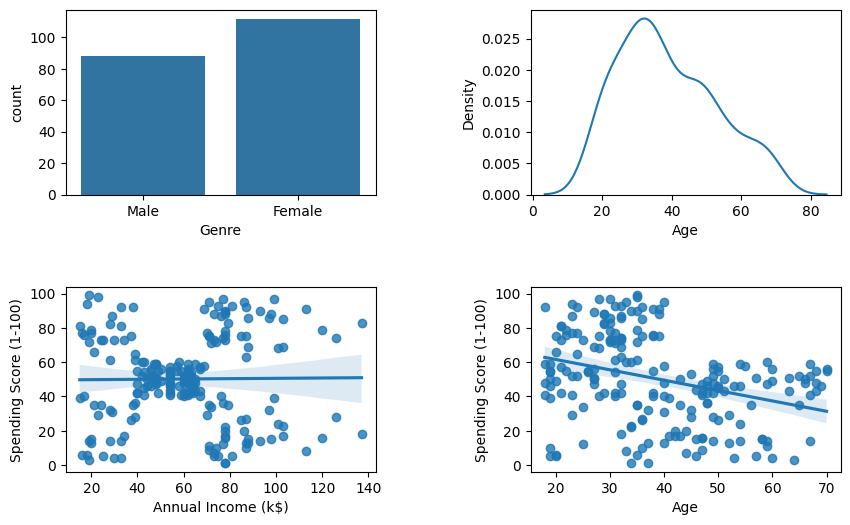

In [143]:
import matplotlib.pyplot as plt
import seaborn as sns
fig,ax=plt.subplots(2,2,figsize=(10,6))
sns.countplot(df,x='Genre',ax=ax[0,0])
sns.kdeplot(df,x='Age',ax=ax[0,1])
sns.regplot(df,x='Annual Income (k$)',y='Spending Score (1-100)',ax=ax[1,0])
sns.regplot(df,x='Age',y='Spending Score (1-100)',ax=ax[1,1])
plt.subplots_adjust(hspace=0.5,wspace=0.5)
plt.show()

## Females are more than males in dataset.
## People earning around $40k to 70k are having spending score 40 to 60.
## As the age is increasing, the spending score is rapidly falling around 40 age group.

In [144]:
df.to_csv('mall.csv',index=False)

In [145]:
from sklearn.preprocessing import StandardScaler,LabelEncoder
le=LabelEncoder()
df['Genre']=le.fit_transform(df['Genre'])

In [146]:
import pickle
with open('le.pkl','wb') as f:
  pickle.dump(le,f)

In [147]:
scaler=StandardScaler()
df[['Age','Annual Income (k$)','Spending Score (1-100)']]=scaler.fit_transform(df[['Age','Annual Income (k$)','Spending Score (1-100)']])

In [148]:
with open('scaler.pkl','wb') as f:
  pickle.dump(scaler,f)

In [149]:
from sklearn.decomposition import PCA
pca=PCA(n_components=2)
pca.fit(df)
df=pca.transform(df)

In [150]:
with open('pca.pkl','wb') as f:
  pickle.dump(pca,f)

In [151]:
from sklearn.cluster import KMeans
wcss=[]
for i in range(1,14):
  kmean=KMeans(i,init='k-means++')
  kmean.fit(df)
  wcss.append(kmean.inertia_)
print(wcss)

[465.98559543545235, 255.27255875927204, 193.51605208193521, 122.98678699822183, 104.11033599840765, 81.83266231463757, 71.56784178447684, 59.5872515134131, 55.36658586134479, 45.33845846765804, 46.04171683366645, 37.269397799166356, 33.135730965709726]


In [152]:
!pip install kneed

np.int64(4)

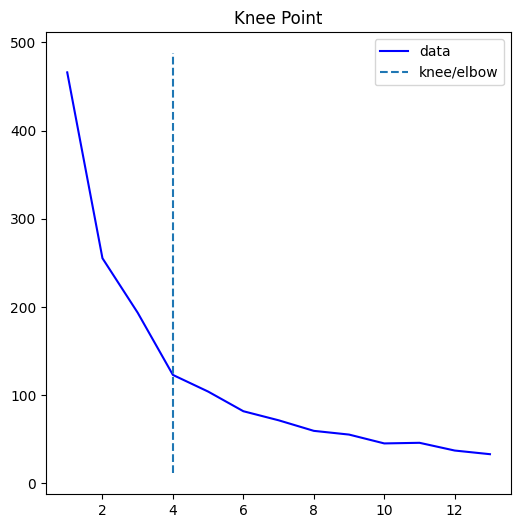

In [153]:
from kneed import KneeLocator
knee=KneeLocator(range(1,14),wcss,curve='convex',direction='decreasing')
knee.plot_knee()
knee.elbow

In [154]:
from sklearn.metrics import silhouette_score
sil=[]
for i in range(2,14):
  knee=KMeans(i,init='k-means++')
  knee.fit(df)
  s=silhouette_score(df,knee.labels_)
  sil.append(s)
print(sil)

[np.float64(0.42530948194519075), np.float64(0.415055702399757), np.float64(0.42325846739759077), np.float64(0.38774958139976134), np.float64(0.3840920458199417), np.float64(0.3745842147245376), np.float64(0.38502387823397016), np.float64(0.34661493134526344), np.float64(0.3867650529233197), np.float64(0.38807247240531545), np.float64(0.35674794745143573), np.float64(0.3763841502379067)]


<module 'matplotlib.pyplot' from '/usr/local/lib/python3.13/dist-packages/matplotlib/pyplot.py'>

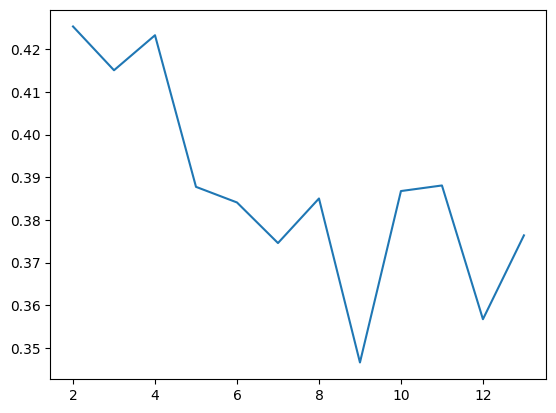

In [155]:
plt.plot(range(2,14),sil)
plt

# 3 Clusters are coming out to be the best option

In [156]:
kmean=KMeans(4,init='k-means++')
kmean.fit(df)
pred=kmean.predict(df)

In [157]:
with open('kmean.pkl','wb') as f:
  pickle.dump(kmean,f)

In [158]:
df[:5]

array([[-0.60043766, -1.73717898],
       [-1.64988591, -1.78912423],
       [ 0.31538132, -1.69277231],
       [-1.47798868, -1.78131664],
       [-0.06054496, -1.67869121]])

In [159]:
pred

array([1, 1, 3, 1, 1, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1,
       3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1,
       3, 1, 3, 1, 1, 1, 3, 1, 1, 3, 3, 3, 3, 3, 1, 3, 3, 1, 3, 3, 3, 1,
       3, 3, 1, 1, 3, 3, 3, 3, 3, 1, 3, 3, 1, 3, 3, 1, 3, 3, 1, 3, 3, 2,
       2, 3, 3, 2, 0, 0, 2, 2, 0, 2, 0, 2, 2, 0, 0, 2, 0, 2, 0, 0, 0, 0,
       0, 2, 0, 2, 2, 2, 0, 0, 0, 0, 2, 0, 2, 2, 2, 2, 0, 2, 0, 2, 0, 2,
       2, 2, 0, 2, 0, 2, 0, 2, 0, 2, 2, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2,
       0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2,
       0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2,
       0, 2], dtype=int32)

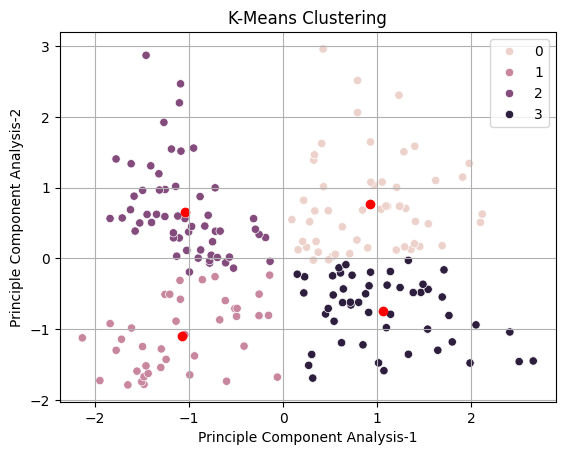

In [160]:
sns.scatterplot(x=df[:,0],y=df[:,1],hue=pred)
plt.scatter(x=kmean.cluster_centers_[:,0],y=kmean.cluster_centers_[:,1],c='red',label='Centroid')
plt.xlabel('Principle Component Analysis-1')
plt.ylabel('Principle Component Analysis-2')
plt.title('K-Means Clustering')
plt.grid()
plt.show()

## Verify the categories:

In [161]:
df=pd.read_csv(path+'/Mall_Customers.csv')
df['Cluster']=pred

In [162]:
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,1
1,2,Male,21,15,81,1
2,3,Female,20,16,6,3
3,4,Female,23,16,77,1
4,5,Female,31,17,40,1


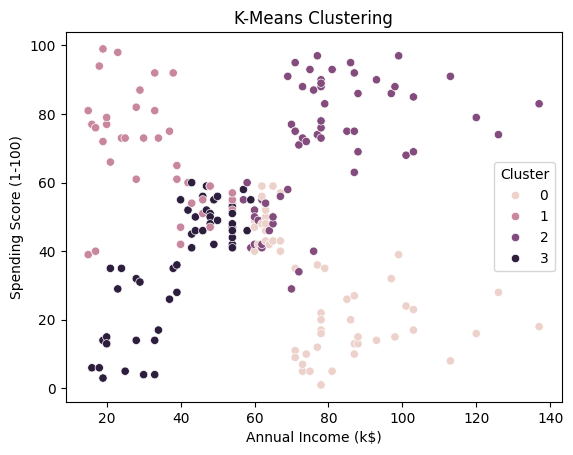

In [163]:
sns.scatterplot(df,x='Annual Income (k$)',y='Spending Score (1-100)',hue='Cluster')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('K-Means Clustering')
plt.show()

## 0 ->  High Earning, Low Spending
## 1 -> Low Earning, High Spending
## 2 -> Low Earning, Low Spending
## 3 -> High Earning, High Spending